# 02 — Klasszikus gépi tanulás: TF-IDF baseline

**Ez a notebook az RQ1 felét és az RQ2 egészét válaszolja meg.**

- **RQ1:** hogyan teljesítenek a klasszikus algoritmusok a transformerhez képest?
  → itt megkapjuk a klasszikus felét; a BERT a 03-as notebookban jön.
- **RQ2:** mennyit számít az előfeldolgozás és a jellemzőreprezentáció?
  → itt egy ablációs táblázattal válaszolunk.

> **Miért fontos a baseline?** Ha a BERT 0,82 macro-F1-et ér el, az önmagában
> semmit nem jelent. Ha viszont tudod, hogy a Logistic Regression 0,76-ot, akkor
> már van mondanivalód: „a transformer +6 pontot hoz, cserébe 40× több
> számításigényért". **Ez a fajta trade-off elemzés emeli meg a dolgozatot.**

## 1. Beállítás és adatbetöltés

In [2]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))

import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from src import set_seed
from src.config import CFG, PATHS, apply_plot_style
from src import data_loading as dl
from src import models_classical as mc
from src import evaluation as ev

set_seed()
apply_plot_style()

# A 01-es notebook mentette el ezeket. Ha hibát kapsz, futtasd le előbb azt!
train_df, val_df, test_df = dl.load_all_splits()

print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")
print(train_df["sentiment"].value_counts().to_string())

train 121,996 | val 40,666 | test 40,666
sentiment
positive    78661
neutral     27368
negative    15967


## 2. A három modell betanítása

**Kritikus módszertani pont:** a TF-IDF vektorizáló és az osztályozó egyetlen
scikit-learn `Pipeline`-ban van. Ez nem kényelmi kérdés — ez akadályozza meg az
**adatszivárgást** (data leakage).

Ha külön illesztenéd a TF-IDF-et az *egész* adathalmazon, akkor a szókincs és az
IDF-súlyok a teszthalmaz információját is tartalmaznák. Az eredményed optimista
lenne, és a bíráló joggal kérdőjelezné meg. A Pipeline-nal a `fit()` csak a
tanító adatot látja, a `predict()` pedig már csak transzformál.

In [5]:
t0 = time.time()
summary, fitted = mc.train_and_evaluate_all(
    train_df, val_df, text_col="text_clean", label_col="sentiment"
)
print(f"\nTeljes tanítási idő: {time.time() - t0:.1f} másodperc\n")

display(summary[["accuracy", "precision_macro", "recall_macro",
                 "f1_macro", "f1_weighted", "n_features"]].round(4))
ev.save_table(summary, "02_classical_validation_results")

12:11:15 | INFO    | src.models_classical | Tanítás: nb (121996 minta)
12:11:26 | INFO    | src.models_classical | Modell elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\tfidf_nb.joblib
12:11:26 | INFO    | src.models_classical | Tanítás: logreg (121996 minta)
12:11:43 | INFO    | src.models_classical | Modell elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\tfidf_logreg.joblib
12:11:43 | INFO    | src.models_classical | Tanítás: svm (121996 minta)
12:12:06 | INFO    | src.models_classical | Modell elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\tfidf_svm.joblib



Teljes tanítási idő: 50.2 másodperc



,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,n_features
model,,,,,,
logreg,0.6395,0.5450,0.5856,0.5563,0.6571,50000
svm,0.6535,0.5277,0.5403,0.5329,0.6538,50000
nb,0.6946,0.5830,0.4924,0.5112,0.6540,50000


12:12:06 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_classical_validation_results.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/02_classical_validation_results.csv')

In [6]:
# Figyeld meg a különbséget a macro és a weighted F1 között!
gap = (summary["f1_weighted"] - summary["f1_macro"]).round(3)
print("weighted_F1 - macro_F1 különbség modellenként:")
print(gap.to_string())
print("\nMinél nagyobb a rés, annál rosszabbul kezeli a modell a kisebbségi "
      "(neutral) osztályt. Ez az egyik legfontosabb megfigyelésed lesz.")

weighted_F1 - macro_F1 különbség modellenként:
model
logreg    0.101
svm       0.121
nb        0.143

Minél nagyobb a rés, annál rosszabbul kezeli a modell a kisebbségi (neutral) osztályt. Ez az egyik legfontosabb megfigyelésed lesz.


## 3. A legjobb modell kiértékelése a TESZT halmazon

In [7]:
# A teszthalmazhoz CSAK MOST nyúlunk, a modellválasztás után. Egyszer.
# Ha többször "belenézel" és aszerint hangolsz, a teszthalmaz elveszti a
# jelentését, és a dolgozatban közölt szám nem lesz becslése a valós teljesítménynek.
best_name = summary.index[0]
best_model = fitted[best_name]
print(f"Legjobb modell a validáción: {best_name}")

y_true = test_df["sentiment"].astype(str)
y_pred = best_model.predict(test_df["text_clean"])

test_metrics = ev.compute_metrics(y_true, y_pred)
print("\n=== TESZT eredmények ===")
for k, v in test_metrics.items():
    print(f"  {k:22s} {v:.4f}")

Legjobb modell a validáción: logreg

=== TESZT eredmények ===
  accuracy               0.6389
  precision_macro        0.5439
  recall_macro           0.5843
  f1_macro               0.5551
  precision_weighted     0.6884
  recall_weighted        0.6389
  f1_weighted            0.6566


In [8]:
# Osztályonkénti bontás — ez a táblázat menjen a dolgozatba.
report = ev.per_class_report(y_true, y_pred)
display(report.round(3))
ev.save_table(report, f"02_{best_name}_test_per_class")

,precision,recall,f1-score,support
negative,0.419,0.608,0.496,5322.000
neutral,0.353,0.425,0.386,9123.000
positive,0.860,0.719,0.783,26221.000
accuracy,0.639,0.639,0.639,0.639
macro avg,0.544,0.584,0.555,40666.000
weighted avg,0.688,0.639,0.657,40666.000


12:12:16 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_logreg_test_per_class.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/02_logreg_test_per_class.csv')

12:12:24 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\02_confusion_matrices_classical.png


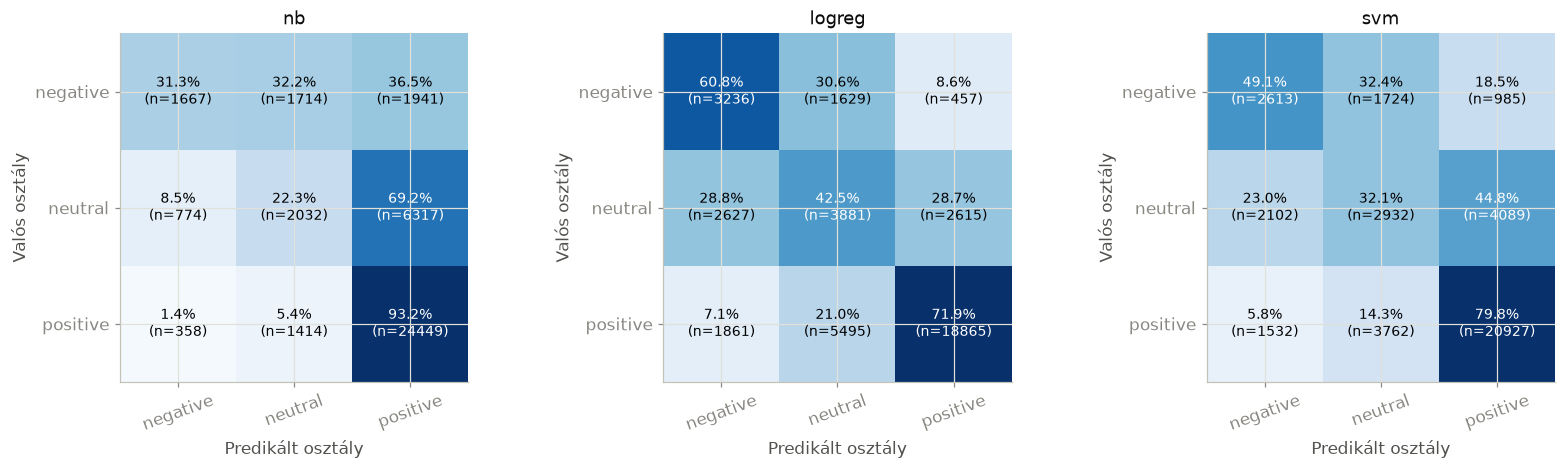

In [9]:
# Confusion matrix mindhárom modellre, egymás mellett.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, mc.MODEL_NAMES):
    pred = fitted[name].predict(test_df["text_clean"])
    ev.plot_confusion_matrix(y_true, pred, title=name, ax=ax)
plt.tight_layout()
ev.save_figure("02_confusion_matrices_classical")
plt.show()

**Amit itt látni fogsz (és le kell írni a dolgozatban):**

A `neutral` sor lesz a leggyengébb — a modell a semleges reviewk jelentős részét
pozitívnak vagy negatívnak tippeli. Ez **nem a modell hibája**, hanem a feladaté:
a 6–8 közötti pontszámú reviewk nyelvileg gyakran megkülönböztethetetlenek a
szélsőségesektől. A „semleges" nálunk egy *pontszám-tartomány*, nem egy
nyelvileg jól elkülönülő kategória.

Ez a mondat a hibaelemzés fejezet magja — és összeköti a 4. pontban látott
küszöb-érzékenységi vizsgálattal.

## 4. RQ2 — Ablációs vizsgálat: mit számít az előfeldolgozás?

In [10]:
# Ez percekig futhat (8 variáns × teljes tanítás).
# Fejlesztéshez vegyél kisebb mintát:
abl_train = train_df.sample(min(30_000, len(train_df)), random_state=CFG.random_seed).copy()
abl_val   = val_df.copy()

ablation = mc.preprocessing_ablation(abl_train, abl_val, model_name="logreg")
display(ablation[["accuracy", "f1_macro", "f1_weighted", "n_features"]].round(4))
ev.save_table(ablation, "02_preprocessing_ablation")

12:12:40 | INFO    | src.models_classical | nyers szöveg, unigram                  macro-F1 = 0.5398
12:12:49 | INFO    | src.models_classical | nyers szöveg, uni+bigram               macro-F1 = 0.5514
12:12:52 | INFO    | src.models_classical | teljes tisztítás, unigram              macro-F1 = 0.5369
12:12:57 | INFO    | src.models_classical | teljes tisztítás, uni+bigram           macro-F1 = 0.5495
12:13:06 | INFO    | src.models_classical | teljes tisztítás, uni+bi+trigram       macro-F1 = 0.5481
12:13:12 | INFO    | src.models_classical | teljes tisztítás, sublinear_tf ki      macro-F1 = 0.5502
12:13:17 | INFO    | src.models_classical | teljes tisztítás, max_feat=10k         macro-F1 = 0.5425
12:13:23 | INFO    | src.models_classical | tisztítás, tagadószavak eldobva        macro-F1 = 0.5409


,accuracy,f1_macro,f1_weighted,n_features
variáns,,,,
"nyers szöveg, uni+bigram",0.6404,0.5514,0.6554,50000
"teljes tisztítás, sublinear_tf ki",0.6408,0.5502,0.6553,49670
"teljes tisztítás, uni+bigram",0.6400,0.5495,0.6545,49670
"teljes tisztítás, uni+bi+trigram",0.6400,0.5481,0.6541,50000
"teljes tisztítás, max_feat=10k",0.6281,0.5425,0.6461,10000
"tisztítás, tagadószavak eldobva",0.6328,0.5409,0.6480,48770
"nyers szöveg, unigram",0.6226,0.5398,0.6427,9431
"teljes tisztítás, unigram",0.6192,0.5369,0.6393,8202


12:13:23 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_preprocessing_ablation.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/02_preprocessing_ablation.csv')

12:13:28 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\02_preprocessing_ablation.png


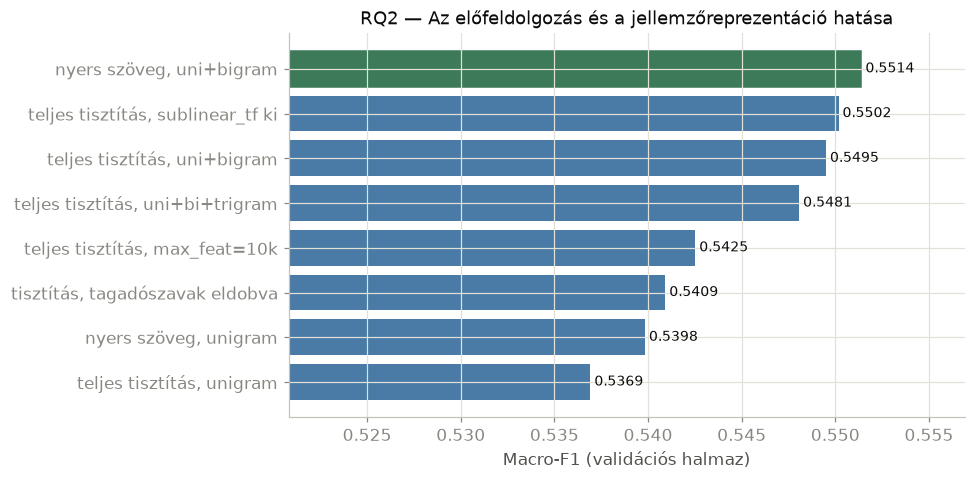


Mit nézz meg:
  1. Mennyit hoz a bigram az unigramhoz képest? (kontextus vs. zsák-a-szavak)
  2. Rontott-e a tagadószavak eldobása? (ha igen: ERŐS érv a dolgozatba)
  3. Segített-e egyáltalán a teljes tisztítás a nyers szöveghez képest?


In [11]:
# Vizualizáció az ablációhoz
fig, ax = plt.subplots(figsize=(9, 4.5))
d = ablation["f1_macro"].sort_values()
bars = ax.barh(d.index, d.values, color="#4a7ba7")
# A legjobb variánst emeljük ki
bars[-1].set_color("#3d7a5a")
ax.set_xlabel("Macro-F1 (validációs halmaz)")
ax.set_xlim(d.min() * 0.97, d.max() * 1.01)
ax.set_title("RQ2 — Az előfeldolgozás és a jellemzőreprezentáció hatása")
for i, v in enumerate(d.values):
    ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
ev.save_figure("02_preprocessing_ablation")
plt.show()

print("\nMit nézz meg:")
print("  1. Mennyit hoz a bigram az unigramhoz képest? (kontextus vs. zsák-a-szavak)")
print("  2. Rontott-e a tagadószavak eldobása? (ha igen: ERŐS érv a dolgozatba)")
print("  3. Segített-e egyáltalán a teljes tisztítás a nyers szöveghez képest?")

## 5. Értelmezhetőség — mely szavak döntenek?

12:13:33 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_top_features_logreg.csv
12:13:34 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\02_top_features_logreg.png


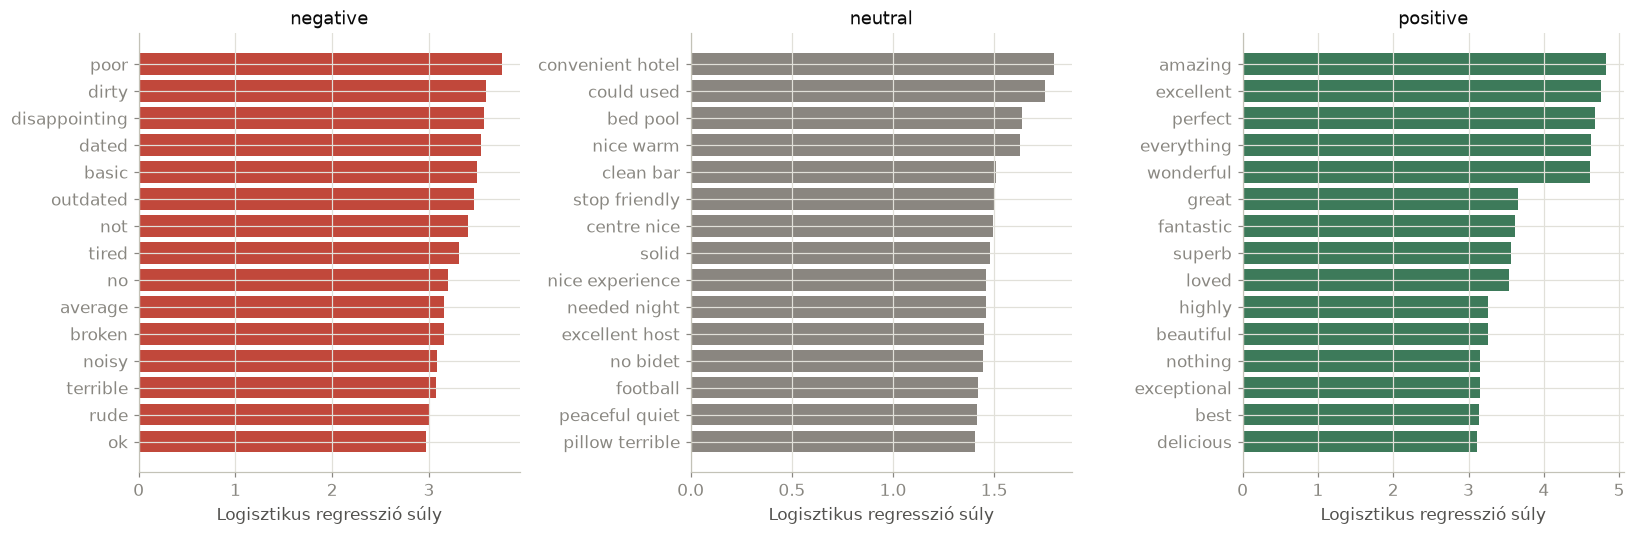

In [12]:
top = mc.top_features_per_class(fitted["logreg"], top_n=15)
ev.save_table(top, "02_top_features_logreg")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = {"negative": "#c1483b", "neutral": "#8a8680", "positive": "#3d7a5a"}
for ax, label in zip(axes, CFG.labels):
    sub = top[top["sentiment"] == label].sort_values("súly")
    ax.barh(sub["jellemző"], sub["súly"], color=colors[label])
    ax.set_title(f"{label}")
    ax.set_xlabel("Logisztikus regresszió súly")
plt.tight_layout()
ev.save_figure("02_top_features_logreg")
plt.show()

**Ez az ábra közvetlenül összeköti a klasszikus modellt az ABSA résszel (RQ3):**
a negatív osztály legnagyobb súlyú jellemzői között ott lesznek az aspektus-szavak
(`dirty`, `noisy`, `smell`, `rude`, `overpriced`). A modell tehát „magától"
megtalálja ugyanazokat az aspektusokat, amiket te a kulcsszólistával definiáltál.

Ez egy erős, jól bemutatható érv a dolgozatban: a két megközelítés
(adatvezérelt vs. lexikon-alapú) **validálja egymást**.

## 6. Hibaelemzés — a dolgozat 8. fejezete kifejezetten kéri

In [13]:
errors = ev.error_analysis(test_df, y_pred, text_col="text",
                           n_examples=8, seed=CFG.random_seed)
ev.save_table(errors, f"02_{best_name}_error_examples")

# OLVASD EL kézzel! Ez a kvalitatív elemzés sokkal értékesebb a bírálónál,
# mint még egy metrika-táblázat.
for _, r in errors.head(12).iterrows():
    print(f"[{r['hibatípus']}]  (score: {r['score']})")
    print(f"  {r['text'][:260]}\n")

12:14:27 | INFO    | src.evaluation | Összes hiba: 14684 / 40666 (36.1%)
12:14:27 | INFO    | src.evaluation | Leggyakoribb hibatípusok:
hibatípus
positive -> neutral     5495
neutral -> negative     2627
neutral -> positive     2615
positive -> negative    1861
negative -> neutral     1629
negative -> positive     457
12:14:27 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_logreg_error_examples.csv


[negative -> neutral]  (score: 7.0)
  Friendly stay. Good mattress, good shower. Lack of microwave oven to warm up milk.

[negative -> neutral]  (score: 7.0)
  Simple, easy going and convinient. A relaxed stay that is well enough placed for a quick jump into town on the metro. The breakfast is worth it to. For those wanting to go into town via public transport, you may a bit of a walk to the nearest metro station. An

[negative -> neutral]  (score: 7.0)
  Great location, amazing views! Great location, great views of Wanaka Lake and the mountain ranges - it was gorgeous and we got a beautiful sunrise view which we loved. Great restaurant downstairs and very close to lots of food places and shops. Modern room wit

[negative -> neutral]  (score: 7.0)
  nice food at the pub and a game of darts no air conditioner

[negative -> neutral]  (score: 7.0)
  Hotel on a busy street. Location is a main point but on the other hand hotel located on a very busy street. Our room window was just above th

In [14]:
# Hibatípusok gyakorisága — jó kis táblázat a dolgozatba
err_all = test_df.copy()
err_all["predicted"] = y_pred
err_all["true"] = y_true
mism = err_all[err_all["predicted"] != err_all["true"]]
tab = (mism["true"] + " -> " + mism["predicted"]).value_counts().to_frame("db")
tab["arány_az_összes_hibából"] = (tab["db"] / len(mism)).round(3)
display(tab)
ev.save_table(tab, "02_error_type_frequency")

,db,arány_az_összes_hibából
positive -> neutral,5495,0.374
neutral -> negative,2627,0.179
neutral -> positive,2615,0.178
positive -> negative,1861,0.127
negative -> neutral,1629,0.111
negative -> positive,457,0.031


12:17:14 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_error_type_frequency.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/02_error_type_frequency.csv')

In [16]:
# Hol hibázik a modell? — találati arány az EREDETI pontszám szerint.
# Ha a 3–5 pontos reviewkat szinte mind negatívnak ismeri fel, a 7-eseket
# viszont nem, akkor a nehézség a címkehatárban van, nem a modellben.
res = test_df.assign(pred=y_pred, true=test_df["sentiment"].astype(str))
res["helyes"] = res["pred"] == res["true"]

by_score = (res.assign(pontszam=res["score"].round().astype(int))
              .groupby("pontszam")
              .agg(n=("helyes", "size"),
                   pontossag=("helyes", "mean"),
                   pred_negative=("pred", lambda s: (s == "negative").mean()),
                   pred_neutral=("pred", lambda s: (s == "neutral").mean()),
                   pred_positive=("pred", lambda s: (s == "positive").mean()))
              .round(3))
display(by_score)
ev.save_table(by_score, "02_accuracy_by_score")

,n,pontossag,pred_negative,pred_neutral,pred_positive
pontszam,,,,,
3,3,1.000,1.000,0.000,0.000
4,26,0.846,0.846,0.115,0.038
5,253,0.874,0.874,0.115,0.012
6,937,0.776,0.776,0.190,0.034
7,4104,0.551,0.552,0.346,0.103
8,9122,0.425,0.288,0.425,0.287
9,10175,0.556,0.119,0.324,0.556
10,16046,0.823,0.040,0.137,0.823


12:35:35 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\02_accuracy_by_score.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/02_accuracy_by_score.csv')

## 7. RQ5 — Cross-dataset általánosítás

In [15]:
# A Boookingon tanított modellt MÁS adathalmazon értékeljük ki.
# Ez válaszolja meg az RQ5-öt: átvihető-e a tudás?
from src import data_loading as dl
from src import preprocessing as pp

# A TripAdvisor MÁS platform -> ez az IGAZI általánosítási teszt.
# (Az 515K Kaggle adat szintén Booking.com-ról származik, csak más időszakból,
#  ezért az egy gyengébb teszt. Érdemes mindkettőt lefuttatni és összevetni!)
try:
    ext_raw = dl.load_dataset_by_name("tripadvisor")
    ext = pp.build_dataset(ext_raw, classic_clean=True, minimal_clean=False)

    ext_pred = best_model.predict(ext["text_clean"])
    ext_metrics = ev.compute_metrics(ext["sentiment"].astype(str), ext_pred)

    comparison = pd.DataFrame({
        "Booking (teszt, in-domain)": test_metrics,
        "TripAdvisor (külső)":        ext_metrics,
    }).round(4)
    display(comparison)
    ev.save_table(comparison, "02_cross_dataset_generalization")

    drop = test_metrics["f1_macro"] - ext_metrics["f1_macro"]
    print(f"\nMacro-F1 romlás: {drop:+.4f} ({drop/test_metrics['f1_macro']:+.1%})")
    print("Magyarázd meg a dolgozatban, MIÉRT: más skála (1-5 vs 1-10), "
          "más felhasználói bázis, más íráskultúra, eltérő reviewhossz.")
except Exception as e:
    print(f"A külső adathalmaz még nem elérhető: {e}")
    print("Töltsd le a Kaggle-ről a data/raw/ mappába, és futtasd újra ezt a cellát.")

A külső adathalmaz még nem elérhető: A(z) 'tripadvisor' adathalmaz ki van kapcsolva. Egyelőre csak a Booking.com adattal dolgozunk (CFG.use_external_datasets = False a config.py-ban). Ha később bevonod, írd át True-ra.
Töltsd le a Kaggle-ről a data/raw/ mappába, és futtasd újra ezt a cellát.


---

## Összefoglaló

**Elmentett eredmények** (`results/`):

| Fájl | Mihez kell |
|---|---|
| `02_classical_validation_results.csv` | RQ1 — klasszikus modellek összehasonlítása |
| `02_preprocessing_ablation.csv/.png` | **RQ2 közvetlen válasza** |
| `02_confusion_matrices_classical.png` | 8. fejezet — hibaszerkezet |
| `02_top_features_logreg.csv/.png` | RQ3 kapcsolódás + értelmezhetőség |
| `02_error_type_frequency.csv` | 8. fejezet — hibaelemzés |
| `02_cross_dataset_generalization.csv` | **RQ5 első fele** |

**A legjobb macro-F1-et jegyezd fel** — ez lesz az a szám, amihez a BERT-et hasonlítod.

**Következő:** `03_bert_colab.ipynb` — töltsd fel Google Colabra, és kapcsolj GPU-t.